# PZ data challenge: results across all task sets

This notebook puts the results of the four task-set notebooks (`pz_challenge_taskset{1..4}_e2e.ipynb`) side by side. It covers all 16 configurations: 4 task sets × 2 sims × 2 depths. It reads the trained ensembles (the subtask 2 `.pkl` model files) those notebooks wrote to `OUT_DIR` (`outputs/znn` from scratch, `outputs/znn_pretrained_popcosmos` with pre-training, set by `PRETRAINING`; plus the method version `RUN` as a suffix) and trains nothing. All p(z)s are predicted here from those models with the current `znn` code, so the p(z) representation is the one `znn` produces now (a Gaussian with the mean and std of the predictions), whatever the run wrote as its own estimate files.

- **Part A, held-out scores** (the subtask 2 model files): each `.pkl` is reloaded and run on the same held-out split the task-set notebook used (`train_test_split` with `VAL_FRAC` and `SEED`). The results are scored with the challenge metrics and tiers. Predictions use the same photometric resampling as the submission (`N_SAMPLES` draws).
- **Part B, comparison with a baseline run**: Part A's held-out scores next to those of an earlier run, read from its held-out cache.
- **Part C, test-set p(z)** (optional, only with `PREDICT_TEST = True`): each model is run on its test file, as for the subtask 1 submission. The test redshifts are hidden, so this part only shows the predictions, i.e. the implied n(z) and the p(z) widths, set against the training redshift distribution.

The held-out and test-set predictions are cached in `CACHE_DIR`, outside `OUT_DIR` so they stay out of the submission tarball. Delete the cache to recompute, e.g. after changing how `znn` builds the p(z).

Run this from the repo root with the `qp` conda env as the kernel.

Plot conventions: **colour = depth** (blue 10yr, orange 1yr) and **line style = sim** (solid Cardinal, dashed Flagship).

## Configuration

In [1]:
import znn  # run from the repo root so this picks up the local source

TASKSETS = [1, 2, 3, 4]
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]
TASKSET_NAMES = {
    1: "1: representative",
    2: "2: spec-selected",
    3: "3: spec + COSMOS",
    4: "4: spec + COSMOS, blended",
}

DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks
# Which run to read; must match the task-set notebooks: "popcosmos" (the pre-training shipped with znn) or None (from scratch). Each choice
# writes to its own directory, so runs with and without pre-training never overwrite each other.
PRETRAINING = "popcosmos"
# Method version, appended to OUT_DIR so runs of different versions never overwrite each other ("" for none):
# the RUN of the task-set notebooks ("noisy_kfold", plus "_frombase" with FROM_BASE); the p(z)s are predicted here
RUN = "noisy_kfold_frombase"
OUT_DIR = ("outputs/znn" if PRETRAINING is None else f"outputs/znn_pretrained_{PRETRAINING}") + (f"_{RUN}" if RUN else "")  # the submission files written by the task-set notebooks
CACHE_DIR = f"{OUT_DIR}_predictions"  # held-out (part A) and test-set (part C) predictions
# Part C, at the end: predict every model's test set (as for the subtask 1 file) and show the implied n(z). It
# takes about as long as the held-out predictions, so it only runs when True
PREDICT_TEST = False
PLOT_DIR = "plots"  # figures are saved here, prefixed with the run name so runs never overwrite each other

# the held-out split: must match the task-set notebooks
VAL_FRAC = 0.2
SEED = 42
# prediction: photometric noise draws per object (converged by 50 on Cardinal Y1) and their seed
N_SAMPLES = 50
NOISE_SEED = 42

I0000 00:00:1793231028.040338 1077400 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import itertools
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

CONFIGS = list(itertools.product(TASKSETS, SIMS, SCENARIOS))
ZGRID = np.linspace(0, 3, 601)  # where p(z)s and the stacked n(z) are evaluated
COLORS = {"10yr": "#2a78d6", "1yr": "#eb6834"}
LINESTYLES = {"cardinal": "-", "flagship": "--"}
TRAIN_COLOR = "0.6"


def style(sim, scenario):
    return dict(color=COLORS[scenario], ls=LINESTYLES[sim], lw=1.5, label=f"{sim} {scenario}")


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{os.path.basename(OUT_DIR)}_{name}.pdf"), bbox_inches="tight")


def path(kind, taskset, sim, scenario):
    if kind in ("training", "test"):
        return os.path.join(DATA_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.hdf5")
    return os.path.join(OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.pkl")


missing = [p for c in CONFIGS if not os.path.exists(p := path("pz_model", *c))]
assert not missing, f"missing model files: {missing}"

## Reference redshifts

These are the same labels as in the task-set notebooks. Task sets 1 and 2 use `redshift`. Task sets 3 and 4 use `redshift` for spectroscopically selected objects and `redshift_manyband` for COSMOS-only objects, so scores on the COSMOS-only objects include the label noise.

In [3]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object, and the held-out subsets to score (masks over train).
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        subsets = {"all": np.ones(len(train), dtype=bool)}
        if (train["mag_i_lsst"] < 23.5).all():
            return z_spec, subsets  # task set 1
        return z_spec, subsets | {"i > 23": train["mag_i_lsst"].to_numpy() > 23}  # task set 2

    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref, {"all": np.ones(len(train), dtype=bool), "spec": is_spec, "COSMOS-only": is_cosmos_only}

# Part A: held-out scores

For each configuration the model file is reloaded and run on the held-out 20% of the training file. The model was trained on the other 80%, the same split as in the task-set notebooks. Each held-out set is scored on all of its objects and on the subsets the task-set notebook reported: task set 2 has `i > 23`, the faintest objects available, and task sets 3 and 4 have spec-selected and COSMOS-only.

Only task set 1 has a held-out set that is representative of its test set. For the other task sets these scores are **optimistic** for the test set.

In [4]:
def heldout_predictions(taskset, sim, scenario):
    # Held-out reference z, i-mag, subset masks, zmode, the p(z) mean and std, and the ensemble's p(z) (a qp
    # ensemble) under "pz". Cached in CACHE_DIR: the arrays in <stem>.npz, the p(z) in <stem>.hdf5.
    stem = os.path.join(CACHE_DIR, f"taskset_{taskset}_{sim}_{scenario}_pz")
    if os.path.exists(f"{stem}.npz") and os.path.exists(f"{stem}.hdf5"):
        return dict(np.load(f"{stem}.npz")) | {"pz": qp.read(f"{stem}.hdf5")}

    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref, subsets = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]

    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED)
    )
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "zmode": np.squeeze(pz.ancil["zmode"]),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        **{f"subset:{name}": mask[idx_val] for name, mask in subsets.items()},
    }
    np.savez(f"{stem}.npz", **out)
    pz.write_to(f"{stem}.hdf5")
    return out | {"pz": pz}


heldout = {}
for c in CONFIGS:
    print("held-out predictions:", *c)
    heldout[c] = heldout_predictions(*c)

held-out predictions: 1 cardinal 1yr


I0000 00:00:1793231103.551011 1077400 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38478 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:03:00.0, compute capability: 8.0
I0000 00:00:1793231103.555322 1077400 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 38478 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:41:00.0, compute capability: 8.0
I0000 00:00:1793231103.559698 1077400 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 38478 MB memory:  -> device: 2, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:82:00.0, compute capability: 8.0
I0000 00:00:1793231103.564806 1077400 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 38478 MB memory:  -> device: 3, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:c1:00.0, compute capability: 8.0
I0000 00:00:1793231105.700707 1079242 service.cc:153] XLA servic

held-out predictions: 1 cardinal 10yr
held-out predictions: 1 flagship 1yr
held-out predictions: 1 flagship 10yr
held-out predictions: 2 cardinal 1yr
held-out predictions: 2 cardinal 10yr
held-out predictions: 2 flagship 1yr
held-out predictions: 2 flagship 10yr
held-out predictions: 3 cardinal 1yr


/global/u2/j/jaimerz/UCL/mlpz_cnn_deepset/znn/data.py:158: RuntimeWarning: invalid value encountered in subtract
  mags_normed = mags - mag_i[None, :]  # normalize by i-band mag, per band, before binning


held-out predictions: 3 cardinal 10yr
held-out predictions: 3 flagship 1yr


...

held-out predictions: 3 flagship 10yr
held-out predictions: 4 cardinal 1yr


/global/u2/j/jaimerz/UCL/mlpz_cnn_deepset/znn/data.py:158: RuntimeWarning: invalid value encountered in subtract
  mags_normed = mags - mag_i[None, :]  # normalize by i-band mag, per band, before binning


held-out predictions: 4 cardinal 10yr
held-out predictions: 4 flagship 1yr


/global/u2/j/jaimerz/UCL/mlpz_cnn_deepset/znn/data.py:158: RuntimeWarning: invalid value encountered in subtract
  mags_normed = mags - mag_i[None, :]  # normalize by i-band mag, per band, before binning


held-out predictions: 4 flagship 10yr


In [5]:
def challenge_metrics(z_ref, zmode, pz):
    # The challenge's seven scored metrics, computed as in the task-set notebooks.
    dz = (zmode - z_ref) / (1 + z_ref)
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pit = PIT(pz, z_ref)
    return {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        # qp derives this from a spline fit to the PIT quantiles and it breaks down (negative or huge values)
        # when PIT piles up at 0 or 1; the challenge evaluator uses the same call, so it is what gets scored
        "outlier": pit.evaluate_PIT_outlier_rate(),
        # what it is meant to measure, computed directly (not scored)
        "pit_outlier_direct": np.mean((pit.pit_samps < 0.0001) | (pit.pit_samps > 0.9999)),
    }, pit.pit_samps


def tier_points(values):
    return {name: sum(lo <= float(values[name]) <= hi for lo, hi in ranges) for name, ranges in scoring.metric_dict.items()}


results, pits = {}, {}
for c, h in heldout.items():
    for key in [k for k in h if k.startswith("subset:")]:
        m = h[key]
        results[(*c, key.removeprefix("subset:"))], pits[(*c, key.removeprefix("subset:"))] = challenge_metrics(
            h["z_ref"][m], h["zmode"][m], h["pz"][np.flatnonzero(m)]
        )

table = pd.DataFrame(results).T[list(scoring.metric_dict) + ["pit_outlier_direct"]]
table.index.names = ["taskset", "sim", "scenario", "subset"]
points = pd.DataFrame({k: tier_points(v) for k, v in results.items()}).T
points.index.names = table.index.names
points["total"] = points.sum(axis=1)
N_MAX = sum(len(r) for r in scoring.metric_dict.values())
table.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
1       cardinal 1yr      all          0.0036  0.0184            0.0014   
                 10yr     all          0.0001  0.0124            0.0001   
        flagship 1yr      all          0.0012  0.0216            0.0012   
                 10yr     all          0.0004  0.0125            0.0000   
2       cardinal 1yr      all          0.0014  0.0240            0.0078   
                          i > 23      -0.0020  0.0388            0.0194   
                 10yr     all          0.0008  0.0151            0.0005   
                          i > 23      -0.0021  0.0191            0.0011   
        flagship 1yr      all         -0.0002  0.0271            0.0074   
                          i > 23      -0.0043  0.0408            0.0164   
                 10yr     all          0.0006  0.0158            0.0001   
                          i > 23      -0.0029  0.0193            0.0003   
3       cardinal 1yr      all          0.0042  0.0289            0.0500   
                          spec         0.0042  0.0194            0.0163   
                          COSMOS-only  0.0078  0.0898            0.1132   
                 10yr     all          0.0011  0.0194            0.0266   
                          spec         0.0006  0.0136            0.0008   
                          COSMOS-only  0.0063  0.0493            0.0714   
        flagship 1yr      all          0.0035  0.0384            0.0853   
                          spec         0.0025  0.0206            0.0036   
                          COSMOS-only  0.0114  0.1019            0.1599   
                 10yr     all         -0.0007  0.0272            0.0426   
                          spec        -0.0013  0.0145            0.0003   
                          COSMOS-only  0.0021  0.0522            0.0775   
4       cardinal 1yr      all          0.0023  0.0286            0.0501   
                          spec         0.0028  0.0181            0.0191   
                          COSMOS-only  0.0022  0.0858            0.1100   
                 10yr     all          0.0053  0.0214            0.0279   
                          spec         0.0053  0.0156            0.0058   
                          COSMOS-only  0.0050  0.0491            0.0682   
        flagship 1yr      all         -0.0028  0.0397            0.0856   
                          spec        -0.0020  0.0213            0.0047   
                          COSMOS-only -0.0004  0.1016            0.1572   
                 10yr     all          0.0008  0.0288            0.0492   
                          spec         0.0012  0.0162            0.0020   
                          COSMOS-only  0.0010  0.0554            0.0885   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
1       cardinal 1yr      all          135.2539  7.600000e-03  0.1237   
                 10yr     all           32.6110  3.500000e-03  0.0613   
        flagship 1yr      all           80.4610  1.100000e-02  0.1046   
                 10yr     all           75.5340  2.420000e-02  0.0969   
2       cardinal 1yr      all           44.7275  9.900000e-03  0.0727   
                          i > 23        10.3949  9.500000e-03  0.0663   
                 10yr     all           57.7822  6.100000e-03  0.0863   
                          i > 23        20.4874  2.600000e-03  0.0910   
        flagship 1yr      all           43.4967  1.220000e-02  0.0699   
                          i > 23        19.8819  8.300000e-03  0.0808   
                 10yr     all           80.6193  2.450000e-02  0.1028   
                          i > 23        32.9028  3.100000e-03  0.1026   
3       cardinal 1yr      all          185.7981  6.800000e-02  0.1548   
                          spec         136.5772  1.190000e-02  0.1628   
                      

### Points against the challenge tiers

There is one point per nested range a metric falls inside, so at most 3 per metric and 21 per configuration (`pz_data_challenge.scoring.metric_dict`). The table uses the `all` held-out subset.

A 0 under `outlier` is usually not a real failure. qp computes that metric from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1, so compare with `pit_outlier_direct` in the table above. The challenge evaluator makes the same call, so these are the points it would award.

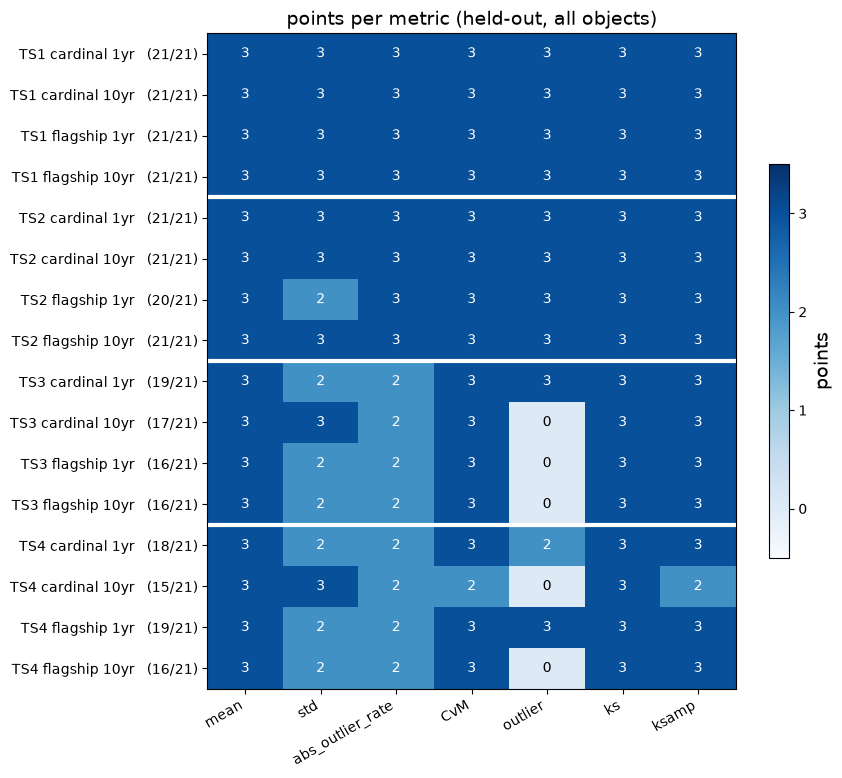

total points per task set (sum over its 4 configurations, held-out all):
taskset
1    84
2    83
3    68
4    68 
(out of 84 each)


In [6]:
pts_all = points.xs("all", level="subset")
labels = [f"TS{t} {s} {y}" for t, s, y in pts_all.index]
metrics = list(scoring.metric_dict)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(pts_all[metrics].to_numpy(), cmap="Blues", vmin=-0.5, vmax=3.5, aspect="auto")
for (i, j), v in np.ndenumerate(pts_all[metrics].to_numpy()):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=10, color="white" if v >= 2 else "black")
ax.set_xticks(range(len(metrics)), metrics, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), [f"{l}   ({t}/{N_MAX})" for l, t in zip(labels, pts_all["total"])])
for y in (3.5, 7.5, 11.5):
    ax.axhline(y, color="white", lw=3)
ax.set_title("points per metric (held-out, all objects)")
fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3], shrink=0.6, label="points")
fig.tight_layout()
save(fig, "points")
plt.show()

print("total points per task set (sum over its 4 configurations, held-out all):")
print(pts_all["total"].groupby(level="taskset").sum().to_string(), f"\n(out of {4 * N_MAX} each)")

### Subsets

These are the same metrics on the task-set-specific subsets. Task set 2's `i > 23` subset is the closest proxy for its faint test set. In task sets 3 and 4, `COSMOS-only` is the faint, test-like part, scored against noisy many-band labels.

In [7]:
sub = table.drop(index="all", level="subset")
sub_points = points.drop(index="all", level="subset")["total"].rename(f"points (/{N_MAX})")
pd.concat([sub, sub_points], axis=1).round(4)

mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
2       cardinal 1yr      i > 23      -0.0020  0.0388            0.0194   
                 10yr     i > 23      -0.0021  0.0191            0.0011   
        flagship 1yr      i > 23      -0.0043  0.0408            0.0164   
                 10yr     i > 23      -0.0029  0.0193            0.0003   
3       cardinal 1yr      spec         0.0042  0.0194            0.0163   
                          COSMOS-only  0.0078  0.0898            0.1132   
                 10yr     spec         0.0006  0.0136            0.0008   
                          COSMOS-only  0.0063  0.0493            0.0714   
        flagship 1yr      spec         0.0025  0.0206            0.0036   
                          COSMOS-only  0.0114  0.1019            0.1599   
                 10yr     spec        -0.0013  0.0145            0.0003   
                          COSMOS-only  0.0021  0.0522            0.0775   
4       cardinal 1yr      spec         0.0028  0.0181            0.0191   
                          COSMOS-only  0.0022  0.0858            0.1100   
                 10yr     spec         0.0053  0.0156            0.0058   
                          COSMOS-only  0.0050  0.0491            0.0682   
        flagship 1yr      spec        -0.0020  0.0213            0.0047   
                          COSMOS-only -0.0004  0.1016            0.1572   
                 10yr     spec         0.0012  0.0162            0.0020   
                          COSMOS-only  0.0010  0.0554            0.0885   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
2       cardinal 1yr      i > 23        10.3949  9.500000e-03  0.0663   
                 10yr     i > 23        20.4874  2.600000e-03  0.0910   
        flagship 1yr      i > 23        19.8819  8.300000e-03  0.0808   
                 10yr     i > 23        32.9028  3.100000e-03  0.1026   
3       cardinal 1yr      spec         136.5772  1.190000e-02  0.1628   
                          COSMOS-only   57.8067  2.967410e+01  0.1475   
                 10yr     spec           6.8153  1.600000e-03  0.0397   
                          COSMOS-only   60.2087 -2.208797e+10  0.1446   
        flagship 1yr      spec          45.7641  1.890000e-02  0.1037   
                          COSMOS-only  120.5848  1.879520e+01  0.1767   
                 10yr     spec          28.8642  4.370000e-02  0.0953   
                          COSMOS-only  100.6375 -6.156416e+02  0.1528   
4       cardinal 1yr      spec          62.3690  1.110000e-02  0.1080   
                          COSMOS-only   56.4830  1.107132e+03  0.1373   
                 10yr     spec         236.3987  2.410000e-02  0.2000   
                          COSMOS-only   61.3716 -1.245796e+08  0.1539   
        flagship 1yr      spec          42.0668  3.290000e-02  0.1198   
                          COSMOS-only  104.9947 -9.500000e-03  0.1484   
                 10yr     spec          58.3123  3.460000e-02  0.1232   
                          COSMOS-only  100.5717 -3.219112e+03  0.1543   

                                          ksamp  pit_outlier_direct  \
taskset sim      scenario subset                                      
2       cardinal 1yr      i > 23        57.3608              0.0113   
                 10yr     i > 23        93.1599              0.0074   
        flagship 1yr      i > 23        91.8984              0.0089   
                 10yr     i > 23       138.4518              0.0061   
3       cardinal 1yr      spec         515.6317              0.0114   
                          COSMOS-only  286.6666              0.0681   
                 10yr     spec          40.2489              0.0055   
                          COSMOS-only  289.2998              0.0787   
        flagship 1yr      spec         208.7868              0.0170   
  

### PIT

PIT histograms on the `all` held-out subset. A flat histogram means the p(z) is calibrated. A U shape means it is too narrow, and a hump means it is too wide.

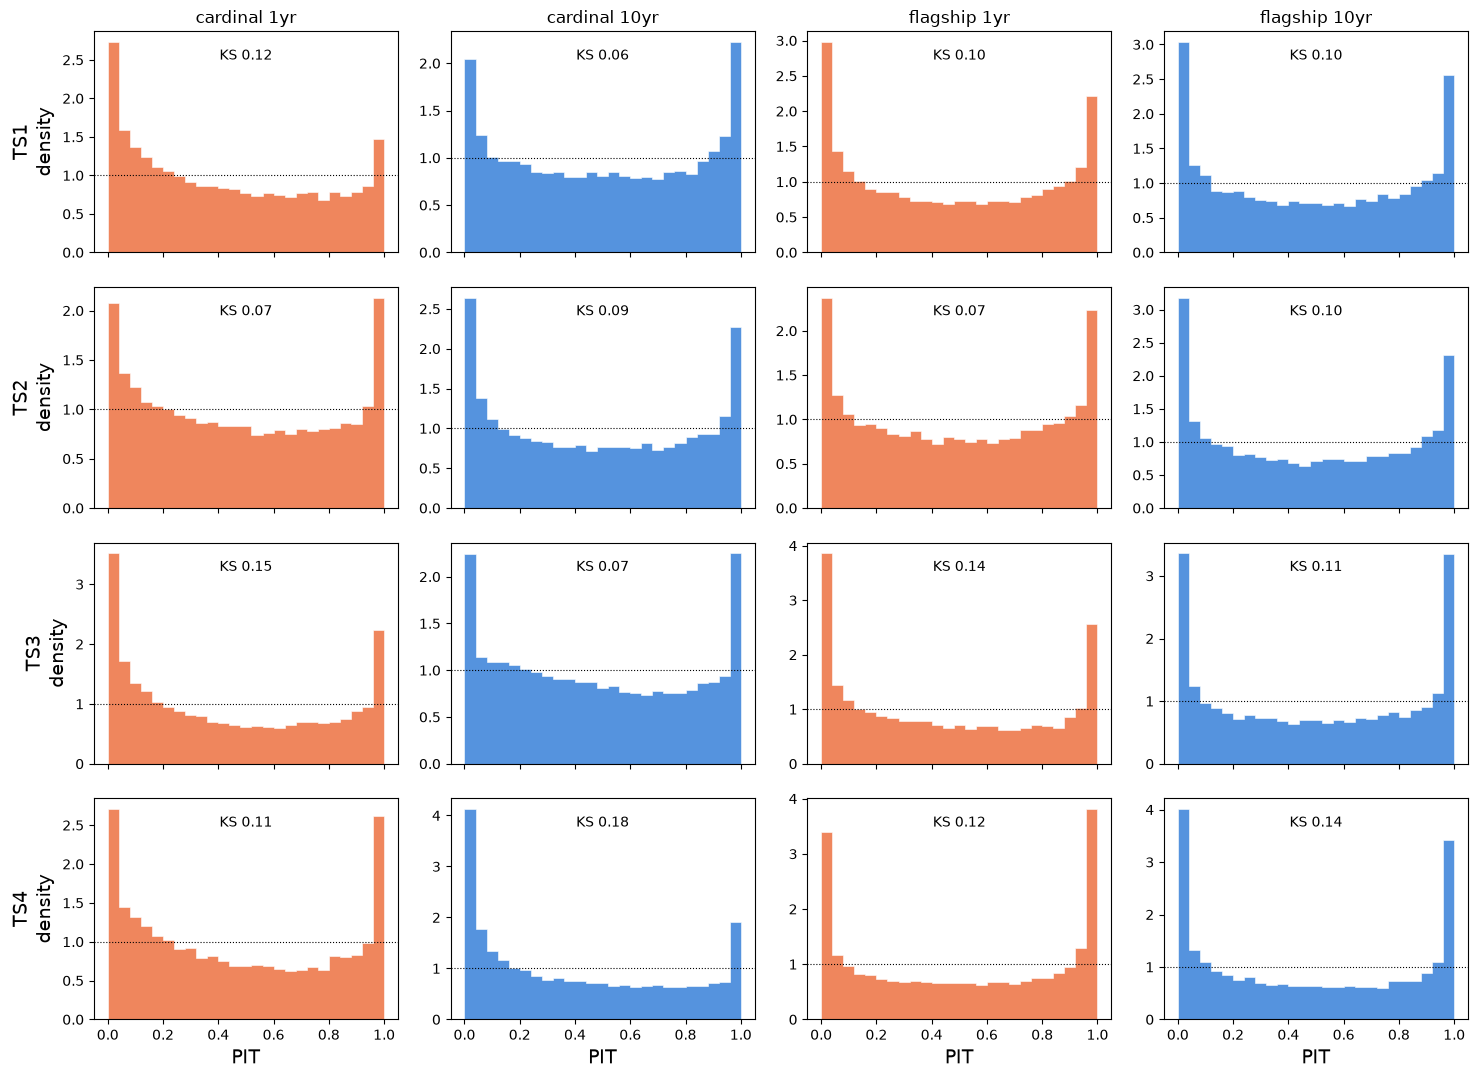

In [8]:
pit_bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        ax.hist(pits[(taskset, sim, scenario, "all")], pit_bins, density=True, color=COLORS[scenario],
                histtype="stepfilled", alpha=0.8, ec="white", lw=0.5)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ks = table.loc[(taskset, sim, scenario, "all"), "ks"]
        ax.text(0.5, 0.92, f"KS {ks:.2f}", transform=ax.transAxes, ha="center", va="top", fontsize=10)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\ndensity")
        if row == 3:
            ax.set_xlabel("PIT")
fig.tight_layout()
save(fig, "pit")
plt.show()

### Point estimates

`zmode` against the reference redshift on the `all` held-out subset (log-density 2D histogram). The dashed lines mark |Δz|/(1+z) = 0.2, the outlier threshold.

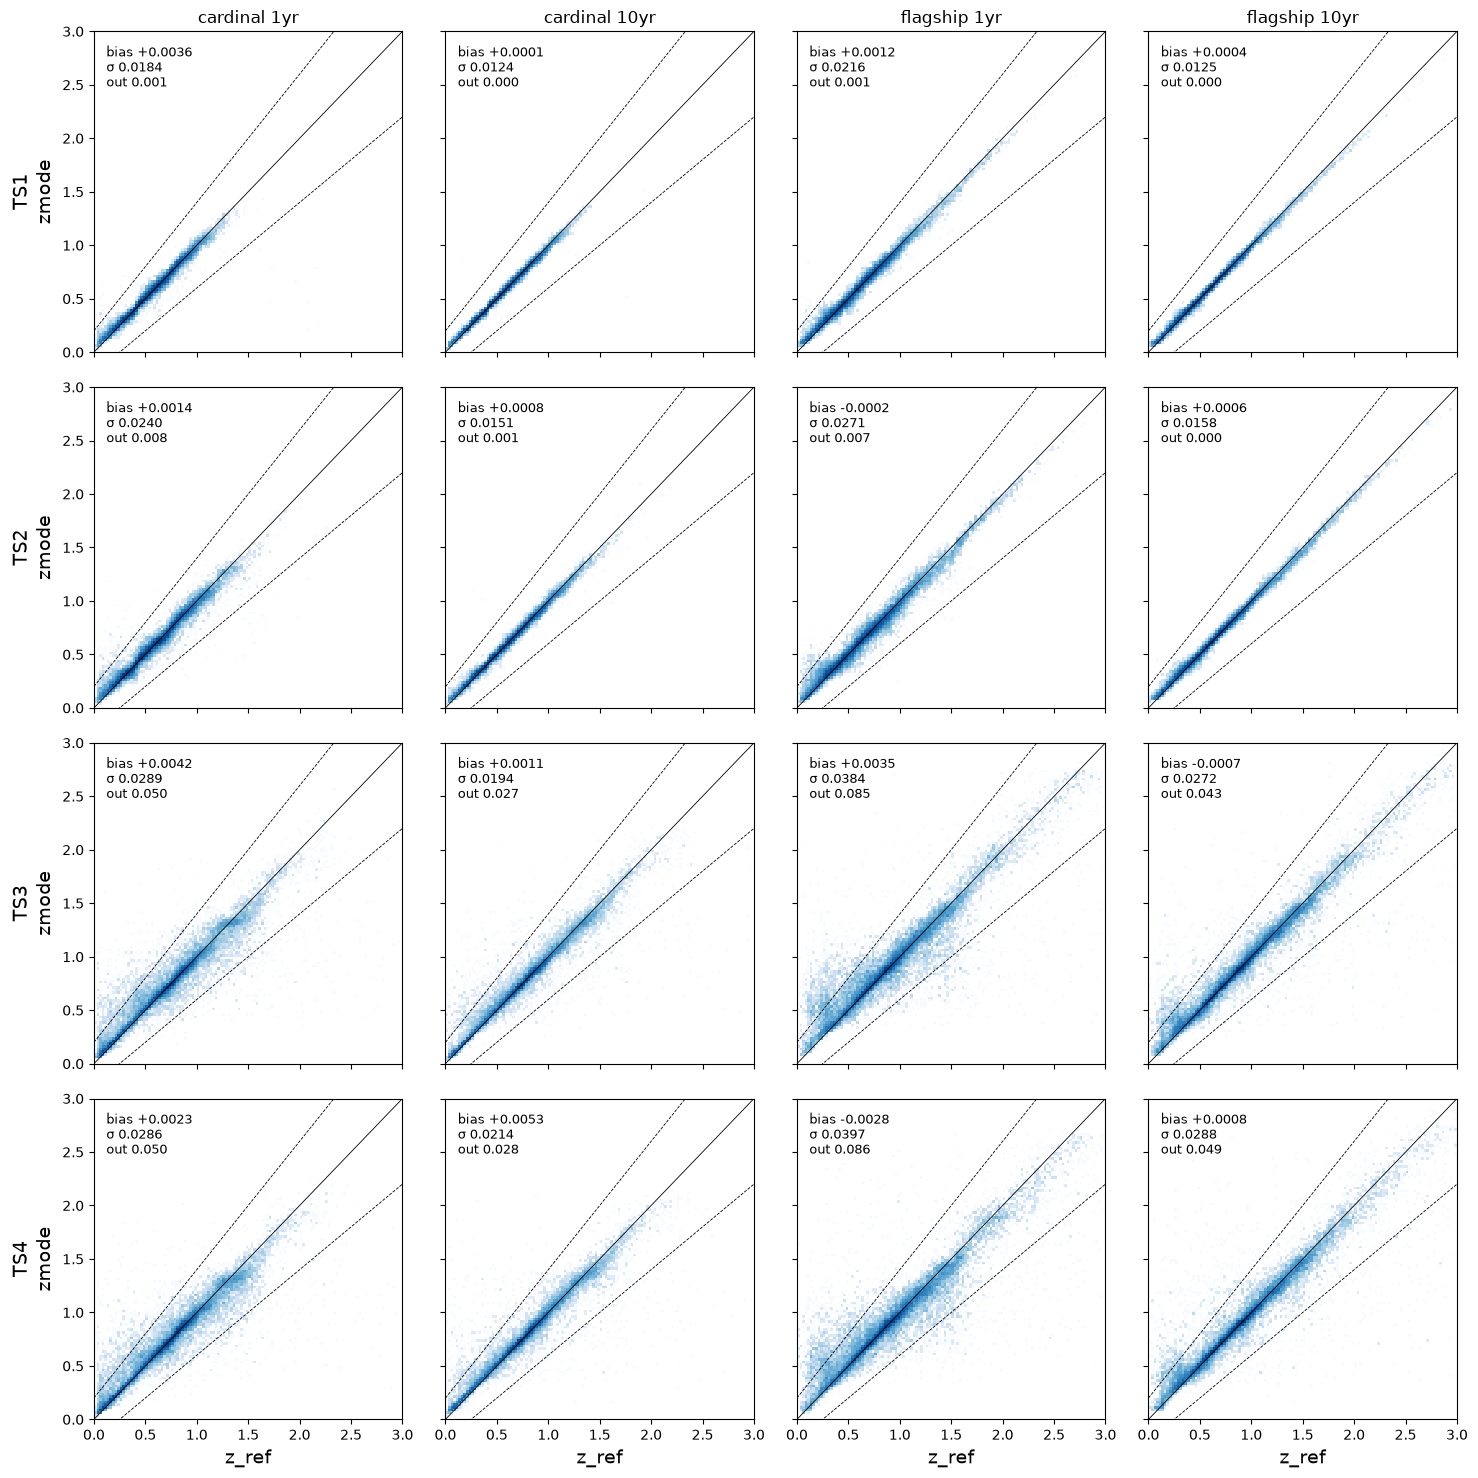

In [9]:
from matplotlib.colors import LogNorm

zb = np.linspace(0, 3, 121)
fig, axes = plt.subplots(4, 4, figsize=(15, 15), sharex=True, sharey=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        h = heldout[(taskset, sim, scenario)]
        ax.hist2d(h["z_ref"], h["zmode"], bins=[zb, zb], cmap="Blues", norm=LogNorm(), rasterized=True)
        ax.plot(zb, zb, color="k", lw=0.6)
        for sgn in (-1, 1):
            ax.plot(zb, zb + sgn * 0.2 * (1 + zb), color="k", lw=0.6, ls="--")
        v = table.loc[(taskset, sim, scenario, "all")]
        ax.text(0.04, 0.96, f"bias {v['mean']:+.4f}\nσ {v['std']:.4f}\nout {v['abs_outlier_rate']:.3f}",
                transform=ax.transAxes, va="top", fontsize=9)
        ax.set_xlim(0, 3)
        ax.set_ylim(0, 3)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\nzmode")
        if row == 3:
            ax.set_xlabel("z_ref")
fig.tight_layout()
save(fig, "zphot_vs_zref")
plt.show()

# Part B: comparison with a baseline run

Part A's held-out scores next to those of an earlier run, read from that run's held-out cache. The baseline is the run before the noise realizations (no `RUN` suffix): every member trained on the catalogue photometry as given, on its own K-fold cut of the training objects, starting from its own pre-trained popcosmos member, and a Gaussian p(z) with the mean and std of the `N_SAMPLES` × members predictions. Its cache holds `z_ref`, `mag_i`, `mean`, `std` and the subset masks per configuration. Configurations missing from the cache are predicted from the baseline's model files (`BASELINE_OUT_DIR`) and added to it. It is scored here exactly as that version scored it, with the Gaussian mean as the point estimate.

Both runs use the same held-out split (`VAL_FRAC`, `SEED`), so they are scored on the same objects; this is checked.

In [10]:
# The baseline run: its OUT_DIR, with its model files, and its held-out cache (<BASELINE_OUT_DIR>_heldout:
# z_ref, mag_i, mean, std and the subset masks per configuration). A configuration missing from the cache
# (e.g. on a machine where the baseline was never scored) is predicted from its model file and added to it.
BASELINE_OUT_DIR = "outputs/znn_pretrained_popcosmos"
BASELINE_LABEL = "baseline"
NEW_LABEL = RUN or "new"
BASELINE_CACHE = f"{BASELINE_OUT_DIR}_heldout"
os.makedirs(BASELINE_CACHE, exist_ok=True)


def baseline_heldout(taskset, sim, scenario):
    cache = os.path.join(BASELINE_CACHE, f"taskset_{taskset}_{sim}_{scenario}.npz")
    if os.path.exists(cache):
        return dict(np.load(cache))
    model_file = os.path.join(BASELINE_OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_pz_model_{scenario}.pkl")
    assert os.path.exists(model_file), f"no baseline held-out cache or model file for {(taskset, sim, scenario)}: {model_file}"
    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref, subsets = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]
    trained_models, features = znn.load_ensemble_file(model_file)
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED))
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        **{f"subset:{name}": mask[idx_val] for name, mask in subsets.items()},
    }
    np.savez(cache, **out)
    return out


base_results, base_pits = {}, {}
for c in CONFIGS:
    b = baseline_heldout(*c)
    assert np.array_equal(b["z_ref"], heldout[c]["z_ref"]), f"{c}: the baseline was scored on different held-out objects"
    for key in [k for k in b if k.startswith("subset:")]:
        m = b[key]
        pz = qp.Ensemble(qp.stats.norm, data={"loc": b["mean"][m, None], "scale": b["std"][m, None]})
        base_results[(*c, key.removeprefix("subset:"))], base_pits[(*c, key.removeprefix("subset:"))] = challenge_metrics(
            b["z_ref"][m], b["mean"][m], pz
        )

base_table = pd.DataFrame(base_results).T[table.columns]
base_table.index.names = table.index.names
base_points = pd.DataFrame({k: tier_points(v) for k, v in base_results.items()}).T
base_points.index.names = table.index.names
base_points["total"] = base_points.sum(axis=1)

# metrics side by side on the "all" subset, baseline then new for each metric
comparison = pd.concat({BASELINE_LABEL: base_table, NEW_LABEL: table}, axis=1).xs("all", level="subset")
comparison = comparison.swaplevel(axis=1)[[(m, r) for m in table.columns for r in (BASELINE_LABEL, NEW_LABEL)]]
comparison.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence 

mean                           std  \
                          baseline noisy_kfold_frombase baseline   
taskset sim      scenario                                          
1       cardinal 1yr        0.0018               0.0036   0.0178   
                 10yr       0.0007               0.0001   0.0113   
        flagship 1yr        0.0004               0.0012   0.0199   
                 10yr      -0.0002               0.0004   0.0117   
2       cardinal 1yr        0.0038               0.0014   0.0233   
                 10yr       0.0015               0.0008   0.0138   
        flagship 1yr        0.0004              -0.0002   0.0265   
                 10yr       0.0002               0.0006   0.0146   
3       cardinal 1yr        0.0049               0.0042   0.0274   
                 10yr       0.0034               0.0011   0.0187   
        flagship 1yr        0.0006               0.0035   0.0390   
                 10yr       0.0036              -0.0007   0.0271   
4       cardinal 1yr        0.0050               0.0023   0.0311   
                 10yr       0.0023               0.0053   0.0191   
        flagship 1yr        0.0029              -0.0028   0.0410   
                 10yr       0.0005               0.0008   0.0283   

                                               abs_outlier_rate  \
                          noisy_kfold_frombase         baseline   
taskset sim      scenario                                         
1       cardinal 1yr                    0.0184           0.0016   
                 10yr                   0.0124           0.0002   
        flagship 1yr                    0.0216           0.0012   
                 10yr                   0.0125           0.0000   
2       cardinal 1yr                    0.0240           0.0088   
                 10yr                   0.0151           0.0005   
        flagship 1yr                    0.0271           0.0070   
                 10yr                   0.0158           0.0001   
3       cardinal 1yr                    0.0289           0.0530   
                 10yr                   0.0194           0.0264   
        flagship 1yr                    0.0384           0.0848   
                 10yr                   0.0272           0.0438   
4       cardinal 1yr                    0.0286           0.0544   
                 10yr                   0.0214           0.0290   
        flagship 1yr                    0.0397           0.0872   
                 10yr                   0.0288           0.0506   

                                                     CvM                       \
                          noisy_kfold_frombase  baseline noisy_kfold_frombase   
taskset sim      scenario                                                       
1       cardinal 1yr                    0.0014   60.0842             135.2539   
                 10yr                   0.0001   33.3644              32.6110   
        flagship 1yr                    0.0012   49.8812              80.4610   
                 10yr                   0.0000   67.6429              75.5340   
2       cardinal 1yr                    0.0078   94.1080              44.7275   
                 10yr                   0.0005   52.8723              57.7822   
        flagship 1yr                    0.0074   50.1886              43.4967   
                 10yr                   0.0001   73.6012              80.6193   
3       cardinal 1yr                    0.0500  197.6953             185.7981   
                 10yr                   0.0266  141.7389              42.3678   
        flagship 1yr                    0.0853  118.8228             157.2665   
                 10yr                   0.0426  280.7299             103.5713   
4       cardinal 1yr                    0.0501  219.4939             105.0681   
                 10yr                   0.0279  133.0587             270.3193   
        flagship 1yr                    0.0856  163.6820             128.6947   
     

In [11]:
# challenge points, per configuration and summed per task set ("all" subset)
pts = pd.DataFrame(
    {
        BASELINE_LABEL: base_points.xs("all", level="subset")["total"],
        NEW_LABEL: points.xs("all", level="subset")["total"],
    }
)
pts["change"] = pts[NEW_LABEL] - pts[BASELINE_LABEL]
print(f"points per configuration (out of {N_MAX}):")
display(pts)
print(f"points per task set (out of {4 * N_MAX}):")
display(pts.groupby(level="taskset").sum())

# every subset, as differences new - baseline: lower is better for |mean|, std, abs_outlier_rate, ks, CvM, ksamp
diff = table[list(scoring.metric_dict)] - base_table[list(scoring.metric_dict)]
diff["|mean|"] = table["mean"].abs() - base_table["mean"].abs()
diff["points"] = points["total"] - base_points["total"]
diff.round(4)

points per configuration (out of 21):


baseline  noisy_kfold_frombase  change
taskset sim      scenario                                        
1       cardinal 1yr             21                    21       0
                 10yr            21                    21       0
        flagship 1yr             21                    21       0
                 10yr            21                    21       0
2       cardinal 1yr             21                    21       0
                 10yr            21                    21       0
        flagship 1yr             20                    20       0
                 10yr            21                    21       0
3       cardinal 1yr             19                    19       0
                 10yr            17                    17       0
        flagship 1yr             16                    16       0
                 10yr            14                    16       2
4       cardinal 1yr             19                    18      -1
                 10yr            20                    15      -5
        flagship 1yr             19                    19       0
                 10yr            17                    16      -1

points per task set (out of 84):


,baseline,noisy_kfold_frombase,change
taskset,,,
1,84,84,0
2,83,83,0
3,66,68,2
4,75,68,-7


mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
1       cardinal 1yr      all          0.0019  0.0007           -0.0002   
                 10yr     all         -0.0006  0.0011           -0.0001   
        flagship 1yr      all          0.0007  0.0017            0.0000   
                 10yr     all          0.0005  0.0008            0.0000   
2       cardinal 1yr      all         -0.0023  0.0007           -0.0009   
                          i > 23      -0.0055  0.0003           -0.0027   
                 10yr     all         -0.0008  0.0014            0.0000   
                          i > 23      -0.0023  0.0005            0.0000   
        flagship 1yr      all         -0.0006  0.0006            0.0003   
                          i > 23      -0.0010  0.0002            0.0000   
                 10yr     all          0.0004  0.0011            0.0000   
                          i > 23      -0.0010  0.0007            0.0000   
3       cardinal 1yr      all         -0.0007  0.0015           -0.0030   
                          spec        -0.0007  0.0013           -0.0010   
                          COSMOS-only -0.0035 -0.0002           -0.0068   
                 10yr     all         -0.0023  0.0007            0.0002   
                          spec        -0.0024  0.0007           -0.0004   
                          COSMOS-only -0.0011  0.0014            0.0012   
        flagship 1yr      all          0.0030 -0.0006            0.0005   
                          spec         0.0022 -0.0008            0.0000   
                          COSMOS-only  0.0051  0.0021            0.0009   
                 10yr     all         -0.0043  0.0001           -0.0012   
                          spec        -0.0041 -0.0004            0.0001   
                          COSMOS-only -0.0048  0.0007           -0.0023   
4       cardinal 1yr      all         -0.0027 -0.0025           -0.0043   
                          spec        -0.0020 -0.0022           -0.0034   
                          COSMOS-only -0.0074 -0.0013           -0.0060   
                 10yr     all          0.0030  0.0023           -0.0010   
                          spec         0.0035  0.0023           -0.0003   
                          COSMOS-only -0.0005  0.0015           -0.0024   
        flagship 1yr      all         -0.0057 -0.0013           -0.0016   
                          spec        -0.0043 -0.0009           -0.0003   
                          COSMOS-only -0.0092  0.0018           -0.0028   
                 10yr     all          0.0003  0.0005           -0.0014   
                          spec         0.0011  0.0007            0.0000   
                          COSMOS-only -0.0012 -0.0001           -0.0027   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
1       cardinal 1yr      all           75.1696 -2.700000e-03  0.0366   
                 10yr     all           -0.7534  1.000000e-03 -0.0054   
        flagship 1yr      all           30.5799  1.800000e-03  0.0280   
                 10yr     all            7.8911 -5.500000e-03  0.0122   
2       cardinal 1yr      all          -49.3805 -2.000000e-04 -0.0274   
                          i > 23         1.5655  2.700000e-03  0.0073   
                 10yr     all            4.9100  2.800000e-03  0.0081   
                          i > 23        18.0053  1.500000e-03  0.0570   
        flagship 1yr      all           -6.6919 -5.900000e-03 -0.0073   
                          i > 23         8.6680  2.000000e-04  0.0215   
                 10yr     all            7.0181 -1.300000e-02  0.0094   
                          i > 23        16.1833  8.000000e-04  0.0265   
3       cardinal 1yr      all          -11.8973  7.600000e-03  0.0030   
                          spec         -10.6728  1.400000e-03  0.0041   
                      

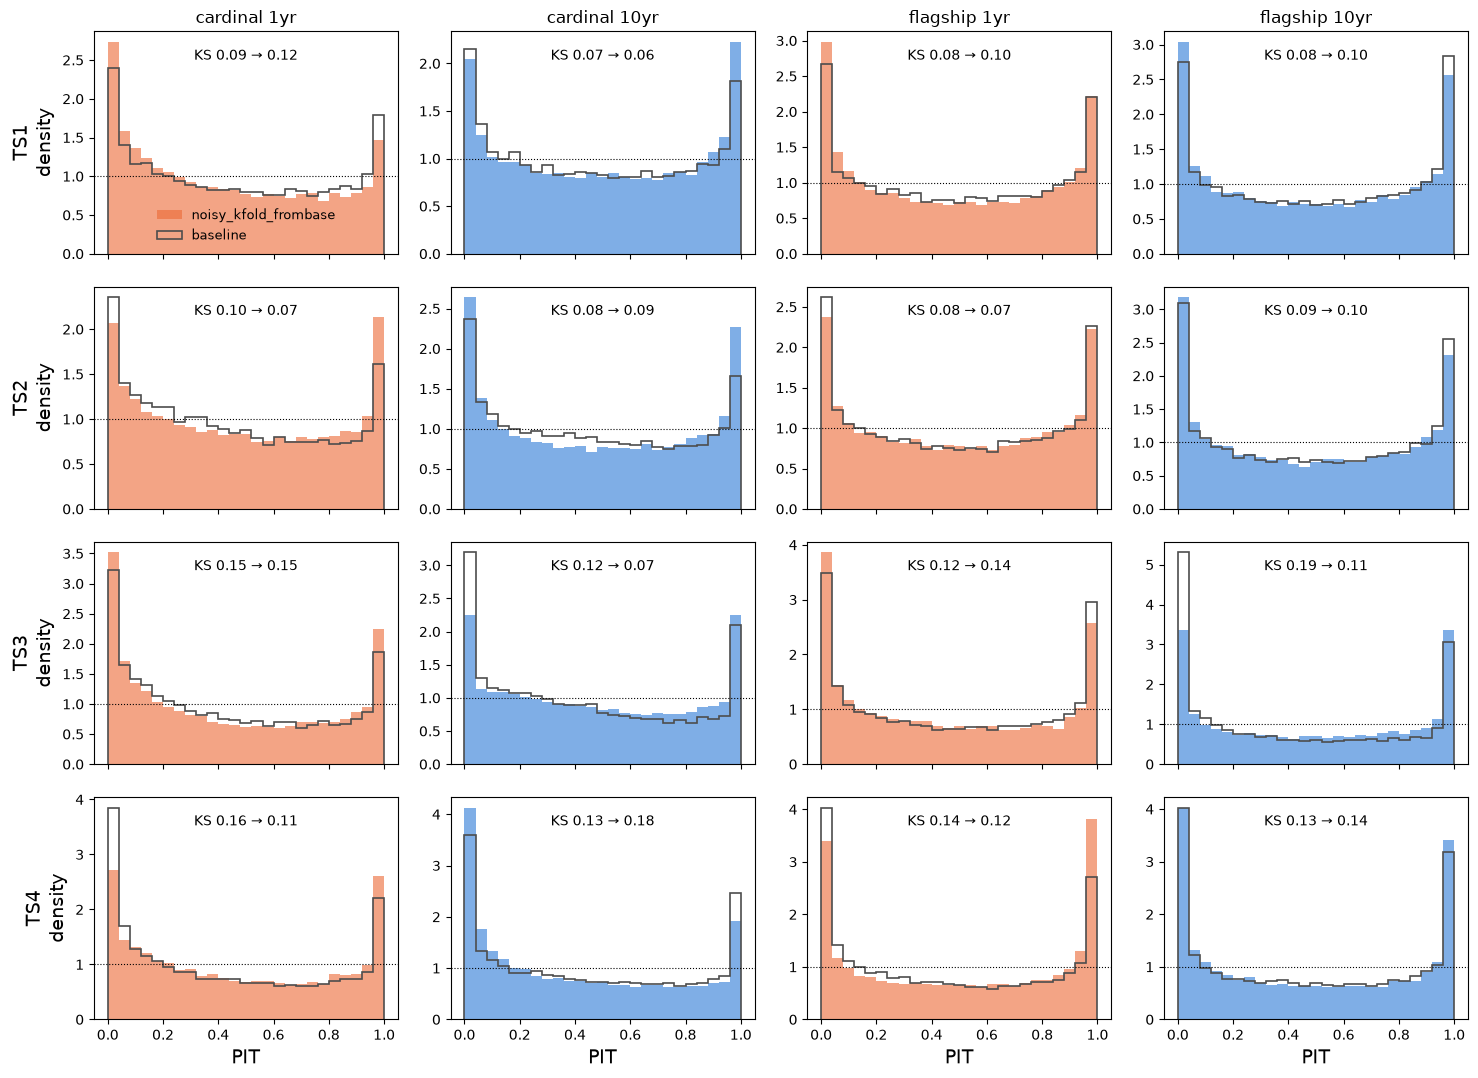

In [12]:
# PIT of the two runs on the "all" held-out subset: baseline outlined in grey, new filled
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        key = (taskset, sim, scenario, "all")
        ax.hist(pits[key], pit_bins, density=True, color=COLORS[scenario], histtype="stepfilled", alpha=0.6,
                label=NEW_LABEL)
        ax.hist(base_pits[key], pit_bins, density=True, color="0.3", histtype="step", lw=1.2, label=BASELINE_LABEL)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.text(0.5, 0.92, f"KS {base_table.loc[key, 'ks']:.2f} → {table.loc[key, 'ks']:.2f}", transform=ax.transAxes,
                ha="center", va="top", fontsize=10)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\ndensity")
        if row == 3:
            ax.set_xlabel("PIT")
axes[0, 0].legend(fontsize=9, frameon=False, loc="lower center")
fig.tight_layout()
save(fig, "pit_vs_baseline")
plt.show()

# Appendix: what the CNN sees

The model does not take the band magnitudes as a list. Each magnitude (minus the reference i band) is spread over wavelength with its filter curve, and the result is averaged into `n_bins` equal-width wavelength bins. This gives a continuous curve (channel 0 of `X`), which is shown here for a few held-out galaxies across redshift.

- **Left:** the encoding of the catalogue photometry, drawn through the `n_bins` bin centres as in `znn.visualize_the_data`. The shaded band is the 16–84% range over `N_DRAWS` photometric resamplings, i.e. the noise the ensemble sees in training and at prediction time. The filter curves are in the strip on top. Bins with no observed band are 0 (and have 0 in the coverage channel).
- **Right:** the predicted p(z) for that galaxy from Part A (built from all its predictions), with the reference redshift as a dashed line.

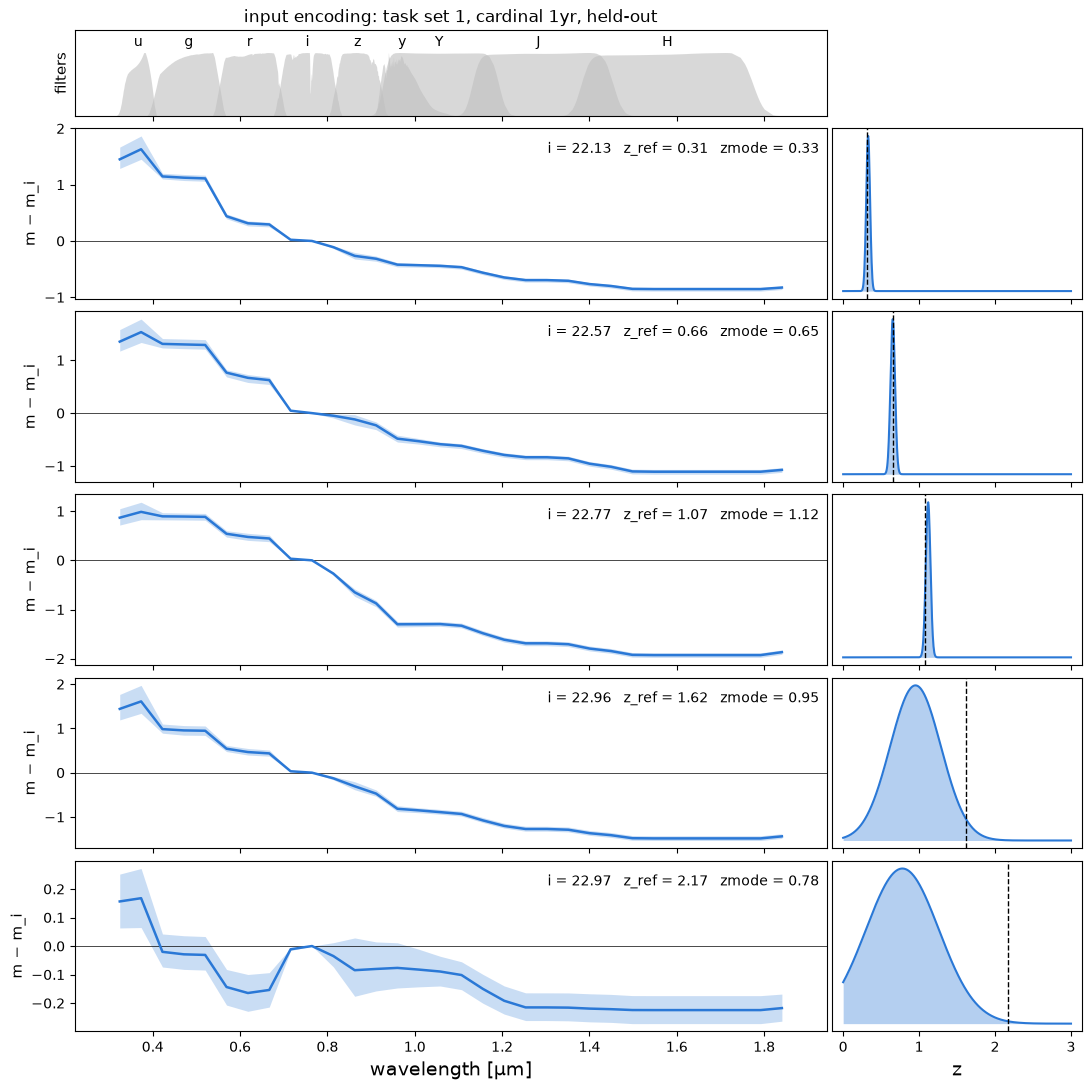

In [13]:
EXAMPLE = (1, "cardinal", "1yr")  # (task set, sim, depth); 1yr makes the photometric errors easier to see
Z_TARGETS = [0.3, 0.7, 1.1, 1.6, 2.2]  # one galaxy picked near each reference redshift
IMAG_RANGE = (22.0, 23.5)  # faint enough for the errors to show
N_DRAWS = 200
rng = np.random.default_rng(1)

train = znn.read_catalog(path("training", *EXAMPLE))
_, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
h = heldout[EXAMPLE]
_, features = znn.load_ensemble_file(path("pz_model", *EXAMPLE))
bands, curves, cfg = features["bands"], features["filter_curves"], features["config"]
errors = {col: f"{col}_err" for col, _ in bands.values()}

in_mag = (h["mag_i"] > IMAG_RANGE[0]) & (h["mag_i"] < IMAG_RANGE[1])
picks = [rng.choice(np.flatnonzero(in_mag & (np.abs(h["z_ref"] - zt) < 0.05))) for zt in Z_TARGETS]
gal = train.iloc[idx_val[picks]]

# wavelength bin centres, as catalog_to_XY builds them
lambda_common = np.linspace(min(c[:, 0].min() for c in curves.values()), max(c[:, 0].max() for c in curves.values()), cfg["n_lambda"])
lam_bins, _ = znn.make_lambda_bins(lambda_common, cfg["n_bins"])
lam_eff = {b: np.sum(c[:, 0] * c[:, 1]) / np.sum(c[:, 1]) for b, c in curves.items()}

X_obs, _ = znn.catalog_to_XY(gal, **features)
enc_draws = [znn.catalog_to_XY(znn.resample_photometry(gal, errors, rng), **features)[0][..., 0] for _ in range(N_DRAWS)]
enc_lo, enc_hi = np.percentile(enc_draws, [16, 84], axis=0)

ENC = "#2a78d6"
um = 1e-4  # filter curves are in Angstrom
fig, axes = plt.subplots(
    len(picks) + 1, 2, figsize=(13, 2.3 * len(picks) + 1.5), sharex="col",
    gridspec_kw=dict(height_ratios=[0.5] + [1] * len(picks), width_ratios=[3, 1], hspace=0.08, wspace=0.01),
)
for b, c in curves.items():
    axes[0, 0].fill_between(c[:, 0] * um, c[:, 1] / c[:, 1].max(), color="0.75", alpha=0.6, lw=0)
    axes[0, 0].text(lam_eff[b] * um, 1.05, b, ha="center", va="bottom", fontsize=10)
axes[0, 0].set_ylim(0, 1.35)
axes[0, 0].set_yticks([])
axes[0, 0].set_ylabel("filters", fontsize=11)
axes[0, 1].axis("off")

for row, (k, j) in enumerate(zip(range(len(picks)), picks), start=1):
    ax = axes[row, 0]
    ax.axhline(0, color="k", lw=0.5)
    ax.fill_between(lam_bins * um, enc_lo[k], enc_hi[k], color=ENC, alpha=0.25, lw=0)
    ax.plot(lam_bins * um, X_obs[k, :, 0], color=ENC, lw=1.8)
    ax.set_ylabel("m − m_i", fontsize=11)
    ax.text(0.99, 0.92, f"i = {h['mag_i'][j]:.2f}   z_ref = {h['z_ref'][j]:.2f}   zmode = {h['zmode'][j]:.2f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=10)

    ax = axes[row, 1]
    pdf = np.squeeze(h["pz"][[j]].pdf(ZGRID))
    ax.fill_between(ZGRID, pdf, color=ENC, alpha=0.35, lw=0)
    ax.plot(ZGRID, pdf, color=ENC, lw=1.5)
    ax.axvline(h["z_ref"][j], color="k", ls="--", lw=1)
    ax.set_yticks([])
axes[-1, 0].set_xlabel("wavelength [μm]")
axes[-1, 1].set_xlabel("z")
axes[0, 0].set_title(f"input encoding: task set {EXAMPLE[0]}, {EXAMPLE[1]} {EXAMPLE[2]}, held-out", fontsize=12)
save(fig, "encoding")
plt.show()

# Part C: test-set p(z)

Runs only with `PREDICT_TEST = True`.


Each model is run on its test file (`N_SAMPLES` noise draws, as for the submission), giving per-object Gaussian p(z)s with the mean and std of all `N_SAMPLES` × members predictions. They are cached in `CACHE_DIR`, and summarised by their `zmode` (the challenge's point estimate), mean and std, and matched to its test catalogue by `object_id` to pick up the i-band magnitude.

In [14]:
def test_predictions(taskset, sim, scenario):
    # The model's test-set p(z) (a qp ensemble), predicted as for the subtask 1 file. Cached in CACHE_DIR.
    cache = os.path.join(CACHE_DIR, f"test_taskset_{taskset}_{sim}_{scenario}_pz.hdf5")
    if os.path.exists(cache):
        return qp.read(cache)
    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    test = znn.read_catalog(path("test", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, test, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED),
        ids=test["object_id"].to_numpy(),
    )
    pz.write_to(cache)
    return pz


def read_estimate(taskset, sim, scenario):
    # Per-object summaries of the test-set p(z), and the stacked n(z) (mean p(z)) on ZGRID.
    pz = test_predictions(taskset, sim, scenario)
    est = pd.DataFrame(
        {
            "object_id": np.squeeze(pz.ancil["object_id"]),
            "zmode": np.squeeze(pz.ancil["zmode"]),
            "mean": np.squeeze(pz.mean()),
            "std": np.squeeze(pz.std()),
        }
    )
    test = znn.read_catalog(path("test", taskset, sim, scenario), columns=["object_id", "mag_i_lsst"])
    est = est.merge(test, on="object_id", how="left", validate="one_to_one")
    assert est["mag_i_lsst"].notna().all()
    return est, pz.pdf(ZGRID).mean(axis=0)


if PREDICT_TEST:
    estimates, stacked_nz, train_z = {}, {}, {}
    for c in CONFIGS:
        print("test-set predictions:", *c)
        estimates[c], stacked_nz[c] = read_estimate(*c)
        train = znn.read_catalog(path("training", *c))
        train_z[c], _ = reference_redshifts(train)

    summary = pd.DataFrame(
        {
            c: {
                "N test": len(e),
                "median zmode": e["zmode"].median(),
                "median σ": e["std"].median(),
                "median σ/(1+z)": (e["std"] / (1 + e["zmode"])).median(),
                "frac z < 0": (e["zmode"] < 0).mean(),
                "median i (test)": e["mag_i_lsst"].median(),
            }
            for c, e in estimates.items()
        }
    ).T
    summary.index.names = ["taskset", "sim", "scenario"]
    display(summary.round(4))


### Implied n(z) of the test set

The stacked test-set p(z) (the mean of the per-object p(z)s) against the training reference redshifts (grey, 10yr file). Task set 1 should agree with training. For task sets 2–4 the test set is fainter than the training set, so any difference between the two shows how far the model has to extrapolate.

In [15]:
if PREDICT_TEST:
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True, sharey=True)
    for col, taskset in enumerate(TASKSETS):
        for row, sim in enumerate(SIMS):
            ax = axes[row, col]
            ax.hist(train_z[(taskset, sim, "10yr")], bins=np.linspace(0, 3, 61), density=True,
                    histtype="stepfilled", color=TRAIN_COLOR, alpha=0.35, label="training z_ref")
            for scenario in SCENARIOS:
                ax.plot(ZGRID, stacked_nz[(taskset, sim, scenario)], **style(sim, scenario))
            ax.axvline(0, color="k", lw=0.5)
            if row == 0:
                ax.set_title(f"task set {TASKSET_NAMES[taskset]}", fontsize=12)
            if row == 1:
                ax.set_xlabel("z")
            if col == 0:
                ax.set_ylabel(f"{sim}\nn(z)")
            ax.legend(fontsize=9, frameon=False)
    fig.tight_layout()
    save(fig, "nz")
    plt.show()